# ICSI263 · Лекц 05: Density Estimation ба GMM

## Томьёог үүсмэл өгөгдөл дээр турших даалгавар

**Нэр:** E.Tuvshin-Erdene  **Оюутны ID:** 23b1num0869  **Огноо:** 2026/10/28

Mean, variance, mixture weight, covariance matrix, MLE ба параметрийн оновчлолыг өөрөө тооцож, Gaussian Mixture Model (GMM)-ийг Expectation–Maximization (EM) алгоритмаар сургана. 

**Өмнөх мэдлэг:** Python функц, NumPy array, broadcasting, матриц үржүүлэх, логарифм, уламжлал, нөхцөлт магадлал. **Санал болгох хугацаа:** 2 × 90 минутын удирдамжтай ажил + 2–3 цагийн бие даалт. Нэмэлт туршилтууд 1–2 цаг.

| Хэсэг | Сэдэв | Оноо | Лекцийн слайд |
|---|---|---:|---|
| 1 | Гараар mean, variance; шугаман хувиргалт | 10 | 5–9 |
| 2 | Gaussian MLE, log-likelihood, numerical optimization | 15 | 13–16, 22–26 |
| 3 | Covariance matrix ба multivariate Gaussian | 15 | 9, 32–33 |
| 4 | Component weight ба холимгийн нийт moment | 10 | 35–40 |
| 5 | E-step: responsibility | 10 | 41–45 |
| 6 | M-step: weight, mean, covariance | 15 | 46–48 |
| 7 | Бүтэн EM ба initialization | 15 | 42–50 |
| 8 | Шинэ өгөгдөл дээр density үнэлэх | 10 | 12, 32, 35–36, 49 |
| **Нийт** | | **100** | |

Эх: багшийн өгсөн **Machine learning Lecture 05 -- Density Estimation and GMM.pptx**, 50 слайд. 8-р хэсгийн heldout үнэлгээ болон нэмэлт туршилтууд нь лекцийг бататгах өргөтгөл.

### Ажиллах дараалал

1. Кодын `TODO` хэсгүүдийг томьёоноос өөрөө хэрэгжүүлнэ. Бэлэн зураг зурах, өгөгдөл үүсгэх, optimizer-ын давталтыг уншиж ашиглана.
2. Хэсэг бүрийн `assert` шалгалтыг давж, график болон тоон үр дүнг тайлбарлана. Эх notebook бодогдоогүй тул эхний TODO дээр зогсох нь хэвийн.
3. Үндсэн бодолтод `np.mean`, `np.var`, `np.cov` болон бэлэн GMM fitting ашиглахгүй. `sum`, `@`, `einsum`, `linalg.solve/cholesky` ашиглаж болно. Шалгалт болон зурагт бэлэн статистик функц ашиглаж болно.
4. Бүх TODO-г дуусгасны дараа **Restart Kernel → Run All** хийнэ. Colab-д **Runtime → Restart session and run all** хэрэглэнэ.
5. `Lab05_StudentID.ipynb` нэрээр график, тоон үр дүн, бүх тайлбартай нь өгнө. Гараар бодсон тооцоогоо Markdown хэсэгт бичнэ. Нэмэлт туршилтууд заавал биш.

Оноог зөвхөн assert давснаар бүрэн авахгүй. Томьёо, хэрэгжилт, үр дүнгийн тайлбар гурвыг хамтад нь үнэлнэ. Хугацаа болон сургалтын системийн эцсийн оноог багш тусад нь зарлана.


## 0. Орчин ба тэмдэглэгээ

Python 3.10+, NumPy 1.26+, Matplotlib 3.8+ хэрэгтэй. JupyterLab эсвэл Google Colab ашиглаж болно. Багц байхгүй бол шинэ нүдэнд `%pip install "numpy>=1.26,<3" "matplotlib>=3.8,<4"` гэж нэг удаа ажиллуулаад kernel-ээ дахин эхлүүлнэ.

- $X$: `(N, D)` өгөгдөл, мөр бүр нэг ажиглалт.
- $\pi$: `(K,)` холимгийн жин, $\pi_k>0, \sum_k\pi_k=1$.
- $\mu$: `(K, D)` component mean.
- $\Sigma$: `(K, D, D)` component covariance.
- $\gamma$: `(N, K)` responsibility, $\gamma_{nk}=p(z_n=k\mid x_n)$.
- $N_k=\sum_n\gamma_{nk}$: component-ийн effective count.

Энд $\pi_k$ нь өгөгдөл харахаас өмнөх component-ийн хувь, $\gamma_{nk}$ нь тухайн $x_n$-ийг харсны дараах харьяалагдах магадлал. $\theta=\{\pi_k,\mu_k,\Sigma_k\}_{k=1}^K$ гэж тууштай тэмдэглэнэ.


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import permutations

SEED = 26305
RUN_OPTIONAL_A = True   # Зөвхөн нэмэлт A-г бөглөсний дараа True болго.
RUN_OPTIONAL_B = True  # Зөвхөн нэмэлт B-г бөглөсний дараа True болго.
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 11})
print('NumPy:', np.__version__, '| seed:', SEED)


NumPy: 2.5.4 | seed: 26305


## 1. Mean ба variance-ийг гараар шалгах · 10 оноо

**Слайд 5–9.** $x=[-2,-1,0,1,2]$-ийн нийлбэр, дундаж, дундажаас хазайлт, хазайлтын квадратын нийлбэрийг гараар бод. Дараа нь `moments_1d`-ийг бич.

$$
\bar x=\frac1N\sum_n x_n,\qquad
v_{ML}=\frac1N\sum_n(x_n-\bar x)^2,\qquad
s^2=\frac1{N-1}\sum_n(x_n-\bar x)^2.
$$

MLE variance нь $N$-ээр, unbiased sample variance нь $N-1$-ээр хуваана. `np.random.normal`-ийн `scale` аргумент нь **standard deviation** тул variance $v$-г өгөхдөө `sqrt(v)` хэрэглэнэ.

**Үнэлгээ:** гараар бодолт 3, функц 4, $y=3x+7$-ийн mean/variance шалгалт ба тайлбар 3.


**Тайлбар бичих:** Жижиг өгөгдлийн гараар бодолтоо энд бич. MLE variance ба unbiased variance яагаад ялгаатай вэ?

TODO: Энд өөрийн тайлбарыг бичнэ.


In [28]:
def moments_1d(x):
    """x: (N,), N>1. Return mean, MLE variance, unbiased variance."""
    x = np.asarray(x, dtype=float)
    # TODO: sum, len болон хазайлтын квадрат ашигла.
    
    mean = np.mean(x)
    variance = np.var(x)
    s2 = np.var(x, ddof=1)
    return mean, variance, s2
    raise NotImplementedError('T1: moments_1d')


In [29]:
x_small = np.array([-2., -1., 0., 1., 2.])
m, v, s2 = moments_1d(x_small)
assert np.allclose([m, v, s2], [0, 2, 2.5])
my, vy, _ = moments_1d(3*x_small + 7)
assert np.isclose(my, 3*m+7) and np.isclose(vy, 9*v)
assert np.isclose(v, np.var(x_small, ddof=0))
assert np.isclose(s2, np.var(x_small, ddof=1))
print('mean, var_ML, var_unbiased =', m, v, s2)
print('y=3x+7: mean, variance =', my, vy)


mean, var_ML, var_unbiased = 0.0 2.0 2.5
y=3x+7: mean, variance = 7.0 18.0


**Тайлбар бичих:** Яагаад 7 нэмэхэд variance өөрчлөгдөөгүй, 3-аар үржүүлэхэд 9 дахин өсөв?

TODO: Энд өөрийн тайлбарыг бичнэ.

7-г нэмэхэд цэг тус бүр 7 оор шилжих тул variance - нь ижилхэн байна.
харин 3 аар үржүүлэхэд $$(3*x - 3 * x_m)^2 = (3(x - x_m))^2 = 9 * (x - x_m)^2 $$ болох тул variance 9 дахин ихэснэ.


## 2. Gaussian MLE ба параметрийн оновчлол · 15 оноо

**Слайд 13–16, 22–26.** $N=400$, жинхэнэ mean $2$, variance $2.25$ бүхий 1D өгөгдөл үүсгэнэ. Жинхэнэ параметр нь бидэнд туршилтын хяналтаар мэдэгдэж байгаа боловч үнэлгээг зөвхөн ажиглалтаас тооцно.

$$
\ell(\mu,v)=-\frac N2\log(2\pi)-\frac N2\log v-\frac1{2v}\sum_n(x_n-\mu)^2.
$$

`gaussian_loglik` нь **нийт** log-likelihood буцаана. `gaussian_grad` нь **дундаж** log-likelihood $\ell/N$-ийн $(\mu,\eta)$, $\eta=\log v$, параметр дэх gradient буцаана:

$$
\frac{\partial(\ell/N)}{\partial\mu}=\frac1{Nv}\sum_n(x_n-\mu),\qquad
\frac{\partial(\ell/N)}{\partial\eta}=-\frac12+\frac1{2Nv}\sum_n(x_n-\mu)^2.
$$

1. MLE mean ба variance-ийг 1-р хэсгийн функцээр тооц.
2. Log-likelihood болон gradient-ийг хэрэгжүүл. Өгсөн gradient-ascent давталт шинэ параметрийг зөвшөөрөхдөө likelihood өссөн эсэхийг шалгана.
3. Эхлэх mean=-1, variance=6 гэсэн утгаас оновчил. Analytic MLE-тэй харьцуулж, likelihood гадаргуу дээр замыг зур.
4. Density-үүдийн үржвэр тоон underflow болж байхад log-likelihood төгсгөлөг байгааг шалга.

**Үнэлгээ:** likelihood 4, gradient 4, optimizer ба analytic MLE харьцуулалт 4, тайлбар 3.


In [30]:
rng_1d = np.random.default_rng(SEED + 1)
x1 = rng_1d.normal(loc=2.0, scale=np.sqrt(2.25), size=400)
mu_ml, var_ml, _ = moments_1d(x1)
print('Generating parameters: mu=2, variance=2.25')
print('Analytic MLE:', mu_ml, var_ml)


Generating parameters: mu=2, variance=2.25
Analytic MLE: 1.9327533685101803 2.2353751381788434


In [31]:
def gaussian_loglik(x, mu, var):
    if var <= 0:
        return -np.inf
    # TODO: нийт log-likelihood, scalar.
    N = len(x)
    loglik = -(N/2) * np.log(2*np.pi) - (N/2) * np.log(var) - np.sum((x-mu)**2) / (2 * var)
    return loglik
    raise NotImplementedError('T2: gaussian_loglik')

def gaussian_grad(x, mu, eta):
    # TODO: дундаж log-likelihood-ийн gradient, shape (2,).
    N = len(x)
    v = np.exp(eta)

    # gradient with respect to mu: 1/(Nv) * sum(x_n - mu)
    grad_mu = np.sum(x - mu) / (N * v)

    # gradient with respect to eta: -1/2 + 1/(2Nv) * sum((x_n - mu)^2)
    grad_eta = -0.5 + np.sum((x-mu) ** 2) / (2 * N * v)

    return np.array([grad_mu, grad_eta])
    raise NotImplementedError('T2: gaussian_grad')


In [32]:
# Өгсөн optimizer: average log-likelihood-д gradient ascent, backtracking.
def optimize_gaussian(x, start=(-1., np.log(6.)), max_iter=1000):
    theta = np.array(start, dtype=float)
    history = [theta.copy()]
    scores = [gaussian_loglik(x, theta[0], np.exp(theta[1])) / len(x)]
    for _ in range(max_iter):
        grad = gaussian_grad(x, *theta)
        if np.linalg.norm(grad) < 1e-7:
            break
        step = 1.0
        for _ in range(40):
            candidate = theta + step*grad
            score = gaussian_loglik(x, candidate[0], np.exp(candidate[1])) / len(x)
            if np.isfinite(score) and score >= scores[-1] + 1e-4*step*(grad@grad):
                break
            step *= 0.5
        else:
            break
        theta = candidate
        history.append(theta.copy())
        scores.append(score)
    return theta, np.array(history), np.array(scores)

theta_opt, opt_path, opt_scores = optimize_gaussian(x1)
mu_opt, var_opt = theta_opt[0], np.exp(theta_opt[1])
assert np.allclose([mu_opt, var_opt], [mu_ml, var_ml], atol=1e-5)
assert np.all(np.diff(opt_scores) >= -1e-12)
# Gradient-ийг томьёог давтаагүй finite difference-ээр шалгах.
point = np.array([0.3, np.log(3.1)])
eps = 1e-5
numeric_grad = np.empty(2)
for j in range(2):
    delta = np.eye(2)[j]*eps
    a, b = point+delta, point-delta
    numeric_grad[j] = (gaussian_loglik(x1, a[0], np.exp(a[1])) -
                       gaussian_loglik(x1, b[0], np.exp(b[1]))) / (2*eps*len(x1))
assert np.allclose(gaussian_grad(x1, *point), numeric_grad, atol=1e-6)
print('Numerical MLE:', mu_opt, var_opt, '| updates:', len(opt_scores)-1)

long_x = np.tile(x1, 10)
log_pdf = -0.5*np.log(2*np.pi*var_ml) - (long_x-mu_ml)**2/(2*var_ml)
print('Naive likelihood product:', np.prod(np.exp(log_pdf)))
print('Stable total log-likelihood:', log_pdf.sum())
assert np.isfinite(log_pdf.sum())


Numerical MLE: 1.9327532367328515 2.235375160438345 | updates: 36
Naive likelihood product: 0.0
Stable total log-likelihood: -7284.572254900042


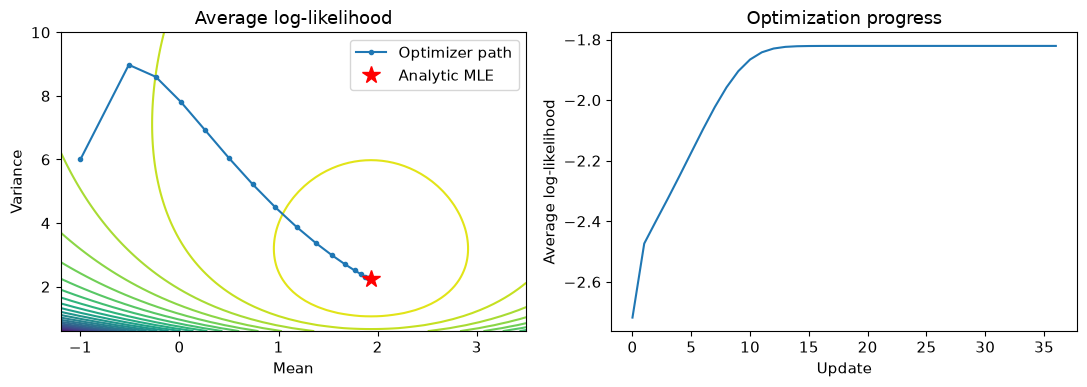

In [33]:
mu_grid = np.linspace(-1.2, 3.5, 85)
v_grid = np.linspace(0.6, 10.0, 100)
surface = np.array([[gaussian_loglik(x1, m, v)/len(x1) for m in mu_grid] for v in v_grid])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cs = axes[0].contour(mu_grid, v_grid, surface, levels=22)
axes[0].plot(opt_path[:, 0], np.exp(opt_path[:, 1]), 'o-', ms=3, label='Optimizer path')
axes[0].plot(mu_ml, var_ml, 'r*', ms=13, label='Analytic MLE')
axes[0].set(xlabel='Mean', ylabel='Variance', title='Average log-likelihood')
axes[0].legend()
axes[1].plot(opt_scores)
axes[1].set(xlabel='Update', ylabel='Average log-likelihood', title='Optimization progress')
plt.tight_layout(); plt.show()


**Тайлбар бичих:** MLE параметр жинхэнэ үүсгэгч параметртэй яг тэнцэх үү? Log авах нь optimum-ийг өөрчлөх үү? Яагаад variance-ийн оронд log-variance оновчилсон бэ?

TODO: Энд өөрийн тайлбарыг бичнэ.

1. 
- N нь дискрет тохиолдолд хэзээ ч яг тэнцэхгүй учир нь тоо хоорондын зай нь continuous тул яг тэнцэх магадлал нь 0-тэй маш ойрхон байна.
- Харин N нь тасралтгүй тохиолдолд үүсгэгч параметр рүү ойртох боловч мөн яг тэнцэхгүй.

2. Log нь монотон функц учир утгуудын байр өөрчлөгдөхгүй тул optimum-ийг өөрчлөхгүй.
3. Variance  нь зөвхөн эерэг тоо байх ёстой ба хэрэв шууд variance-ийн gradient - ийг тооцоолбол log(var)-ыг тооцоолох боломжгүй болно. харин логарифм аван gradient-ийг тооцоолсноор optimizer ямар ч бодит тоогоор өөрчилж болох ба эргээд variance-ийг var = np.exp(eta) тооцоолоход үргэлж эерэг тоо гарна. 


## 3. Covariance matrix ба Gaussian density · 15 оноо

**Слайд 9, 32–33.** $X_{tiny}=[(0,0),(2,1),(0,1),(2,2)]$-ийн mean vector, хоёр variance, covariance-ийг гараар тооц.

$$
\hat\mu=\frac1N\sum_nx_n,\qquad
\hat\Sigma_{ML}=\frac1N\sum_n(x_n-\hat\mu)(x_n-\hat\mu)^T.
$$

$$
\log\mathcal N(x\mid\mu,\Sigma)=-\frac12\left[D\log(2\pi)+\log|\Sigma|+(x-\mu)^T\Sigma^{-1}(x-\mu)\right].
$$

`moments_2d` ба `logpdf_full` бич. `logpdf_full` нь `(N,)` хэмжээтэй log-density буцаана. Ил тод inverse тооцохын оронд Cholesky $LL^T=\Sigma$, `solve(L, delta.T)` хэрэглэж quadratic term-ийг олж болно. Diagonal covariance нь cross-covariance-ийг тэглэнэ. Density-ийн өндөр нь магадлал биш: continuous өгөгдлийн яг нэг цэгийн магадлал 0, интервалын магадлал density-ийн интеграл.

**Үнэлгээ:** гараар матриц 3, moments 4, log-density 5, full/diagonal зураг ба тайлбар 3.


**Тайлбар бичих:** X_tiny-ийн mean vector, covariance matrix-ийг завсрын хазайлтын үржвэрүүдтэй нь бод.

TODO: Энд өөрийн тайлбарыг бичнэ.


In [34]:
def moments_2d(X):
    # TODO: mu (D,), covariance (D,D), N-ээр хуваана.
    N = X.shape[0]
    mu = np.mean(X, axis=0)
    diff = X - mu
    covariance = (diff.T @ diff) / N
    return mu, covariance
    raise NotImplementedError('T3: moments_2d')

def logpdf_full(X, mu, cov):
    # TODO: SPD covariance, Cholesky+solve, result (N,).
    N, D = X.shape
    L = np.linalg.cholesky(cov)
    log_det_cov = 2.0 * np.sum(np.log(np.diagonal(L)))
    diff = X - mu
    z = np.linalg.solve(L, diff.T)
    quad_form = np.sum(z ** 2, axis=0)
    constant = -0.5 * D * np.log(2*np.pi)
    logpdf = constant - 0.5 * log_det_cov - 0.5 * quad_form
    return logpdf
    raise NotImplementedError('T3: logpdf_full')


Tiny mean: [1. 1.] 
Tiny MLE covariance:
 [[1.  0.5]
 [0.5 0.5]]


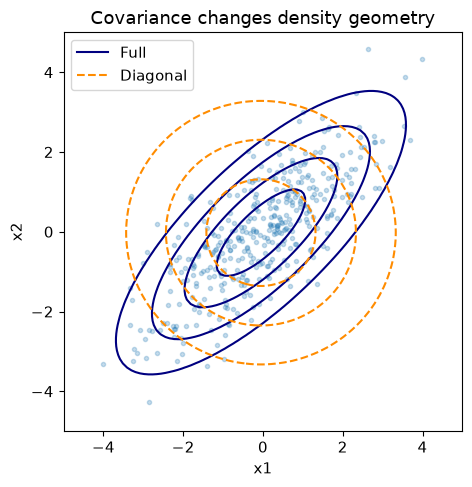

In [35]:
X_tiny = np.array([[0.,0.], [2.,1.], [0.,1.], [2.,2.]])
mu_tiny, cov_tiny = moments_2d(X_tiny)
assert np.allclose(mu_tiny, [1, 1])
assert np.allclose(cov_tiny, [[1, .5], [.5, .5]])
assert np.allclose(cov_tiny, np.cov(X_tiny, rowvar=False, bias=True))
assert np.allclose(cov_tiny, cov_tiny.T) and np.linalg.eigvalsh(cov_tiny).min() > 0
lp = logpdf_full(np.array([[0.,0.], [1.,0.]]), np.zeros(2), np.eye(2))
assert np.allclose(lp, [-np.log(2*np.pi), -np.log(2*np.pi)-0.5])
print('Tiny mean:', mu_tiny, '\nTiny MLE covariance:\n', cov_tiny)

rng_cov = np.random.default_rng(SEED+2)
X_corr = rng_cov.multivariate_normal([0,0], [[2,1.5],[1.5,2]], size=400)
mu_corr, cov_corr = moments_2d(X_corr)
grid_axis = np.linspace(-5, 5, 95)
gx, gy = np.meshgrid(grid_axis, grid_axis)
grid2d = np.column_stack([gx.ravel(), gy.ravel()])
fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(*X_corr.T, s=9, alpha=.25)
for cov, color, style, label in [(cov_corr, 'navy', '-', 'Full'),
                                (np.diag(np.diag(cov_corr)), 'darkorange', '--', 'Diagonal')]:
    density = np.exp(logpdf_full(grid2d, mu_corr, cov)).reshape(gx.shape)
    ax.contour(gx, gy, density, levels=[.005,.02,.05,.09], colors=color, linestyles=style)
    ax.plot([], [], color=color, linestyle=style, label=label)
ax.set(xlabel='x1', ylabel='x2', title='Covariance changes density geometry', aspect='equal')
ax.legend(); plt.tight_layout(); plt.show()


**Тайлбар бичих:** Off-diagonal covariance эерэг байх нь зурагт юу өөрчилсөн бэ? Density 1-ээс их байж болох уу?

TODO: Энд өөрийн тайлбарыг бичнэ.


## 4. Холимгийн жин, mean, нийт covariance · 10 оноо

**Слайд 35–40.** Үүсмэл өгөгдлийг хоёр шаттай үүсгэнэ: эхлээд $z\sim\mathrm{Categorical}(\pi)$, дараа нь $x\mid z=k\sim\mathcal N(\mu_k,\Sigma_k)$.

Энэ хэсэгт л жинхэнэ component label-ийг харж болно. `z_train`-ийг ашиглан ажиглагдсан component бүрийн mean, covariance, $\hat\pi_k=n_k/N$-ийг тооц. Дараах хэсгүүдэд EM-д зөвхөн `X_train` орно. `z_train` нь сургалтын input болохгүй.

Холимгийн нийт covariance нь component-уудын доторх тархалт болон mean-үүдийн хоорондох тархалтыг хамарна:

$$
m=\sum_k\pi_k\mu_k,\qquad
C=\sum_k\pi_k\left[\Sigma_k+(\mu_k-m)(\mu_k-m)^T\right].
$$

**Даалгавар:** component-ийн empirical параметрээр тооцсон нийт moments-ийг бүх өгөгдлөөс шууд тооцсон moments-тэй тулга. Жинхэнэ үүсгэгч параметрээр тооцсон онолын moment ба empirical moment яг адил байх шаардлагагүй.

**Үнэлгээ:** component үнэлгээ 4, mixture moments 4, тайлбар 2.


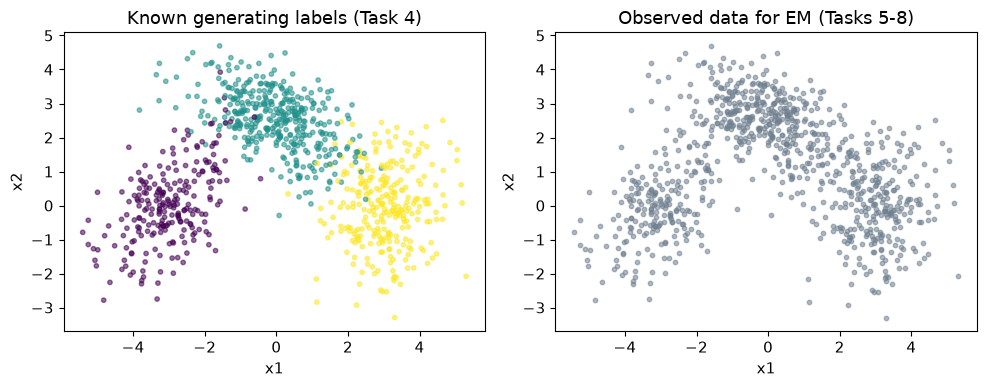

In [36]:
TRUE_PI = np.array([.25, .45, .30])
TRUE_MU = np.array([[-3.,0.], [0.,2.5], [3.,0.]])
TRUE_COV = np.array([[[1.,.65],[.65,1.2]],
                     [[1.2,-.45],[-.45,.8]],
                     [[.7,.1],[.1,1.3]]])

def sample_gmm(n, pi, means, covs, seed):
    rng = np.random.default_rng(seed)
    z = rng.choice(len(pi), size=n, p=pi)
    X = np.empty((n, means.shape[1]))
    for k in range(len(pi)):
        mask = z == k
        X[mask] = rng.multivariate_normal(means[k], covs[k], size=mask.sum())
    return X, z

X_train, z_train = sample_gmm(900, TRUE_PI, TRUE_MU, TRUE_COV, SEED)
# Тусдаа санамсаргүй түүвэр. Параметр тааруулахдаа X_holdout-ийг ашиглахгүй.
X_holdout, _ = sample_gmm(450, TRUE_PI, TRUE_MU, TRUE_COV, SEED+100)
K, D = 3, 2
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].scatter(*X_train.T, c=z_train, cmap='viridis', s=10, alpha=.55)
axes[0].set(title='Known generating labels (Task 4)', xlabel='x1', ylabel='x2')
axes[1].scatter(*X_train.T, color='slategray', s=10, alpha=.55)
axes[1].set(title='Observed data for EM (Tasks 5-8)', xlabel='x1', ylabel='x2')
plt.tight_layout(); plt.show()


In [37]:
def labelled_estimates(X, z, K):
    # TODO: pi (K,), means (K,D), covs (K,D,D).
    # Component тус бүр moments_2d ашиглаж болно.
    N, D = X.shape
    pi = np.zeros(K)
    means = np.zeros((K,D))
    covs = np.zeros((K, D, D))

    for k in range(K):
        mask = (z == k)
        n_k = mask.sum()

        # mixing weight: fraction of points belonging to component k
        pi[k] = n_k / N

        # extract points belonging to component k
        X_k = X[mask]

        # component mean
        means[k] = X_k.mean(axis=0)

        # component covariance
        covs[k] = np.cov(X_k, rowvar=False, ddof = 0)

    return pi, means, covs

    raise NotImplementedError('T4: labelled_estimates')

def mixture_moments(pi, means, covs):
    # TODO: within + between covariance. Return m (D,), C (D,D).
    K, D = means.shape

    # global mean: weighted average of component means
    m = np.sum(pi[:, None] * means, axis = 0)

    # global covariance: within-component variance + between-component variance
    C = np.zeros((D, D))
    for k in range(K):
        diff = means[k] - m
        outer = np.outer(diff, diff) # (mu_k - m)(mu_k - m)^T
        C += pi[k] * (covs[k] + outer)
    return m, C
    raise NotImplementedError('T4: mixture_moments')


In [38]:
pi_label, mu_label, cov_label = labelled_estimates(X_train, z_train, K)
m_empirical, C_empirical = moments_2d(X_train)
m_mix, C_mix = mixture_moments(pi_label, mu_label, cov_label)
assert np.isclose(pi_label.sum(), 1) and np.all(pi_label > 0)
assert np.allclose(m_mix, m_empirical) and np.allclose(C_mix, C_empirical)
# Гараар шалгах 1D mixture: means=-2,+2, component variance=1 -> total variance=5.
tm, tc = mixture_moments(np.array([.5,.5]), np.array([[-2.],[2.]]), np.array([[[1.]],[[1.]]]))
assert np.allclose(tm, [0]) and np.allclose(tc, [[5]])
print('Generating weights:', TRUE_PI, '| observed weights:', pi_label)
print('Component empirical means:\n', mu_label)
print('Component empirical covariances:\n', cov_label)
print('Global empirical covariance:\n', C_empirical)
print('Weighted within-component covariance only:\n', (pi_label[:,None,None]*cov_label).sum(axis=0))


Generating weights: [0.25 0.45 0.3 ] | observed weights: [0.26 0.43 0.31]
Component empirical means:
 [[-2.9977  0.0174]
 [-0.0254  2.5143]
 [ 3.0374 -0.0452]]
Component empirical covariances:
 [[[ 0.8406  0.5429]
  [ 0.5429  1.2823]]

 [[ 1.2243 -0.4701]
  [-0.4701  0.7456]]

 [[ 0.6699  0.0587]
  [ 0.0587  1.3224]]]
Global empirical covariance:
 [[ 6.1266 -0.2885]
 [-0.2885  2.6345]]
Weighted within-component covariance only:
 [[ 0.9527 -0.0428]
 [-0.0428  1.064 ]]


**Тайлбар бичих:** Яагаад зөвхөн component covariance-уудын weighted average нь нийт covariance биш вэ? Observed weight нь TRUE_PI-тай яг тэнцэх үү?

TODO: Энд өөрийн тайлбарыг бичнэ.
1. Учир нь зөвхөн component covariance - уудын жинлэгдсэн дундаж нь зөвхөн тухайн тархалт дотор өгөгдлүүд хэрхэн тархсан байгааг харуулна. Харин нийт тархалтууд нэгэнтэйгээ хэрхэн тархсаныг мөн харгалзаж үзэх хэрэгтэй.
2. Өгөгдлийн тоо төгсгөлөг тул үргэлж TRUE_PI - аас тодорхой хэмжээнд зөрүүтэй байна. Харин өгөгдлийн тоо хязгааргүй руу ойртох тусам TRUE_PI руу мөн хязгааргүй ойртоно.


## 5. E-step: soft assignment · 10 оноо

**Слайд 41–45.** Загварын параметр өгөгдсөн үед component label үл мэдэгдсэн ч posterior-ийг тооцож болно:

$$ 
gamma_{nk}=\frac{\pi_k\mathcal N(x_n\mid\mu_k,\Sigma_k)}
{\sum_j\pi_j\mathcal N(x_n\mid\mu_j,\Sigma_j)}.
$$


Слайд 45, 49-ийн numerator дахь индексийг энд $k$ гэж бичив. Үл мэдэгдэх $z_n$-ийн утгыг урьдчилан ашиглахгүй. `e_step` нь responsibility `(N,K)` болон ажиглалт бүрийн log-density `(N,)` буцаана. Нийт observed-data log-likelihood нь `log_density.sum()`.

Тогтвортой тооцохын тулд $a_{nk}=\log\pi_k+\log\mathcal N(x_n\mid\mu_k,\Sigma_k)$, $b_n=\operatorname{logsumexp}_k a_{nk}$, $\gamma_{nk}=\exp(a_{nk}-b_n)$ хэрэглэнэ. `logsumexp` helper өгөгдсөн.

**Үнэлгээ:** implementation 6, normalization/numerical checks 2, тайлбар 2.


In [39]:
def logsumexp_rows(A):
    """Finite (N,K) log-values -> (N,), stable normalization."""
    max_a = A.max(axis=1, keepdims=True)
    return max_a[:,0] + np.log(np.exp(A-max_a).sum(axis=1))


In [40]:
def e_step(X, pi, means, covs):
    # TODO: log_joint[:,k], log_density, gamma.
    # logpdf_full болон logsumexp_rows helper ашигла.
    # Return gamma (N,K), log_density (N,).
    N, D = X.shape
    K = len(pi)

    # initialize an array to hold log joint probabilities: a_nk = log(pi_k) + log N(x_n | mu_k, Sigma_k)
    A = np.zeros((N, K))

    for k in range(K):
        # calculate log-prior for component k
        log_pi_k = np.log(pi[k])

        # calculate log-PDF of data X under component k using logpdf_full
        log_pdf_k = logpdf_full(X, means[k], covs[k])

        # combine them: a_nk = log(pi_k) + log_pdf_k
        A[:, k] = log_pi_k + log_pdf_k

    # computing logsumexp across columns (axis=1) to get b_n = log(sum_j exp(a_nj))
    # total marginal log_likelihood for each data point
    b_n = logsumexp_rows(A)

    # compute responsibilities in log-space: log(gamma_nk) = a_nk - b_n
    gamma = np.exp(A - b_n[:, None])

    # total log-density for each data point is b_n
    log_density = b_n

    return gamma, log_density
    raise NotImplementedError('T5: e_step')


Most uncertain five x values:
 [[2.2323 1.5721]
 [1.904  1.0024]
 [1.4424 0.4892]
 [2.2699 1.5734]
 [2.2025 1.4309]]
Their responsibilities:
 [[0.     0.4825 0.5175]
 [0.     0.4688 0.5312]
 [0.     0.4609 0.5391]
 [0.     0.4541 0.5459]
 [0.     0.4516 0.5484]]
Extreme-point stable posterior: [[0. 1.]] | log density: [-499002.1121]


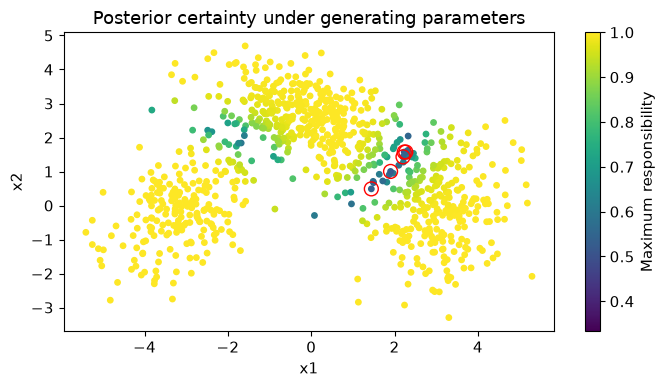

In [41]:
# Symmetric hand-check: x=0 equally near means=-1,+1, equal variances and priors.
g_sym, ld_sym = e_step(np.array([[0.]]), np.array([.5,.5]),
                      np.array([[-1.],[1.]]), np.array([[[1.]],[[1.]]]))
assert np.allclose(g_sym, [[.5,.5]])
g_prior, _ = e_step(np.array([[0.]]), np.array([.8,.2]),
                   np.array([[-1.],[1.]]), np.array([[[1.]],[[1.]]]))
assert np.allclose(g_prior, [[.8,.2]])
# Extreme point: ordinary PDF exponentials underflow, posterior remains valid.
g_far, ld_far = e_step(np.array([[1000.]]), np.array([.5,.5]),
                     np.array([[-1.],[1.]]), np.array([[[1.]],[[1.]]]))
assert np.isfinite(ld_far).all() and np.allclose(g_far.sum(axis=1), 1)

# TRUE параметрийг энэ хэсэгт Bayes posterior туршихад ашиглана, EM initialization-д ашиглахгүй.
gamma_demo, log_density_demo = e_step(X_train, TRUE_PI, TRUE_MU, TRUE_COV)
assert gamma_demo.shape == (len(X_train), K)
assert np.allclose(gamma_demo.sum(axis=1), 1)
assert np.all((gamma_demo >= 0) & (gamma_demo <= 1+1e-12))
uncertain_idx = np.argsort(gamma_demo.max(axis=1))[:5]
print('Most uncertain five x values:\n', X_train[uncertain_idx])
print('Their responsibilities:\n', gamma_demo[uncertain_idx])
print('Extreme-point stable posterior:', g_far, '| log density:', ld_far)

fig, ax = plt.subplots()
sc = ax.scatter(*X_train.T, c=gamma_demo.max(axis=1), vmin=1/K, vmax=1, cmap='viridis', s=15)
ax.scatter(*X_train[uncertain_idx].T, facecolors='none', edgecolors='red', s=100)
ax.set(xlabel='x1', ylabel='x2', title='Posterior certainty under generating parameters')
fig.colorbar(sc, ax=ax, label='Maximum responsibility')
plt.tight_layout(); plt.show()


**Тайлбар бичих:** π_k=0.8 ба γ_nk=0.8 нь ямар ялгаатай утгатай вэ? Хамгийн ойр mean-ийг сонгох нь GMM posterior-той үргэлж адил уу?

TODO: Энд өөрийн тайлбарыг бичнэ.

1. 
- π_k=0.8 нь prior weight буюу өгөгдлүүдийг харгалзан үзэхээс өмнөх, таамгаар ямар ч өгөгдөл сонгоход k component-д харьяалагдах магадлал.
- y_nk = 0.8 нь posterior responsibility буюу нөхцөлт, өгөгдөлд суурилсан магадлал.

2. 
- Хамгийн ойр mean-г сонгох нь K-means hard clustering-аас ялгаагүй ба GMM posterior нь covariance болон prior weight-үүдийг харгалзан үздэг.


## 6. M-step: weight, mean, covariance шинэчлэх · 15 оноо

**Слайд 46–48.** Responsibility өгөгдсөн үед шинэ параметрүүдийг тооц:

$$
N_k=\sum_n\gamma_{nk},\quad \pi_k^{new}=N_k/N,\quad
\mu_k^{new}=\frac1{N_k}\sum_n\gamma_{nk}x_n,
$$


$$
\Sigma_k^{new}=\frac1{N_k}\sum_n\gamma_{nk}
(x_n-\mu_k^{new})(x_n-\mu_k^{new})^T.
$$


Covariance-д **шинэ** mean хэрэглэнэ. Хуваарь нь $N_k$, $N_k-1$ биш. `(delta.T * gamma[:,k]) @ delta` гэж weighted outer product-ийг векторчилж болно.

`covariance_type='diag'` үед шинэ full covariance-ийн зөвхөн diagonal-ийг үлдээ. `reg>0` үед covariance-д `reg*I` нэмэх боломж оруул. Үндсэн ажилд `reg=0` хэрэглэнэ. Empty component ($N_k\le10^{-12}$) бол утгагүй хуваалт хийхээс өмнө `ValueError` өг.

**Үнэлгээ:** $N_k$, weight 4, mean 4, covariance 5, тайлбар 2.


In [42]:
def m_step(X, gamma, covariance_type='full', reg=0.0):
    # TODO: Nk (K,), pi (K,), means (K,D), covs (K,D,D).
    # gamma мөр бүр нийлбэр=1, Nk жижиг бол ValueError.
    # Return pi, means, covs. reg >= 0.
    N, D = X.shape
    K = gamma.shape[1]

    # Effective number of points assigned to each component
    Nk = gamma.sum(axis=0)  # shape(K,)

    # check for empty components to avoid division by zero
    if np.any(Nk <= 1e-12):
        raise ValueError("Empty component detected: Nk is too small (<= 1e-12)")

    # update mixing weights
    pi = Nk / N # shape(K,)

    # update comment means
    # gamma.T has shape (K, N), X has shape (N, D) -> result is (K, D)
    means = (gamma.T @ X) / Nk[:, None] # shape (K, D)

    # update component covariances
    covs = np.zeros((K, D, D))
    for k in range(K):
        diff = X - means[k] # shape(N, D)

        # weighted outer product vectorization trick: (diff.T * gamma[:,k]) @ diff
        # diff.T is (D, N), multiplied by broadcasted gamma[:, k] (N,), @ diff (N, D) -> (D, D)
        covs[k] = (diff.T * gamma[:, k]) @ diff / Nk[k]

        # if covariance_type is 'diag', zero out off-diagonal elements
        if covariance_type == 'diag':
            covs[k] = np.diag(np.diagonal(covs[k]))

        # add regularization if requested (reg * I)
        if reg > 0:
            covs[k] += reg * np.eye(D)

    return pi, means, covs

    raise NotImplementedError('T6: m_step')


In [43]:
# Fractional-count fixture with answers calculable by hand.
X_m = np.array([[0.],[2.],[4.]])
g_m = np.array([[1.,0.],[.5,.5],[0.,1.]])
p_m, m_m, c_m = m_step(X_m, g_m)
assert np.allclose(g_m.sum(axis=0), [1.5,1.5])
assert np.allclose(p_m, [.5,.5])
assert np.allclose(m_m[:,0], [2/3,10/3])
assert np.allclose(c_m[:,0,0], [8/9,8/9])
# One-hot responsibility нь label мэдэгдсэн MLE-тэй яг таарна.
onehot = np.eye(K)[z_train]
p_h, m_h, c_h = m_step(X_train, onehot)
assert np.allclose(p_h, pi_label) and np.allclose(m_h, mu_label) and np.allclose(c_h, cov_label)
p_new, m_new, c_new = m_step(X_train, gamma_demo)
assert np.isclose(gamma_demo.sum(), len(X_train))
assert np.isclose(p_new.sum(), 1) and np.all(p_new>0)
assert np.allclose(c_new, c_new.transpose(0,2,1))
assert np.linalg.eigvalsh(c_new).min()>0
print('Effective counts:', gamma_demo.sum(axis=0))
print('Updated weights:', p_new)
print('Updated means:\n', m_new)
print('Updated covariances:\n', c_new)


Effective counts: [230.583  392.5089 276.9081]
Updated weights: [0.2562 0.4361 0.3077]
Updated means:
 [[-3.0146 -0.0194]
 [-0.0225  2.5116]
 [ 3.0338 -0.0609]]
Updated covariances:
 [[[ 0.8476  0.5049]
  [ 0.5049  1.1883]]

 [[ 1.2858 -0.4794]
  [-0.4794  0.7489]]

 [[ 0.6859  0.0645]
  [ 0.0645  1.2989]]]


**Тайлбар бичих:** N_k яагаад бутархай байж болох вэ? Covariance-д хуучин mean эсвэл N_k−1 хэрэглэвэл ямар алдаа гарах вэ?

TODO: Энд өөрийн тайлбарыг бичнэ.
1. Posterior responsibility - нь магадлал (0-1 бутархай) ба N_k нь тэдгээрийн нийлбэр тул N_k нь бутархай тоо байж болно.
2. M алхамд хамгийн оптимал төвүүдийг олохын тулд шинэ mean-ийг тооцоолдог. Хэрэв хуучин mean ашиглабал гарах covariance matrix нь оптимал байж чадахгүй.

Учир нь N-k-1 -д хуваах нь MLE - тай нийцэхгүй ба хэрэв N_k нь 1-ээс бага weight-тэй бол N_k-1 нь сөрөг тоо болоход хүрнэ.


## 7. EM-ээр GMM сургах · 15 оноо

**Слайд 42–50.** Initial parameter $\theta^{(0)}$-оос эхлээд E-step, M-step-ийг ээлжлүүл. `fit_em` нь зөвхөн `X` авна. Initialization helper нь training data-аас mean сонгох бөгөөд жинхэнэ label/parameter харахгүй.

**Буцаах dictionary:** `pi`, `means`, `covs`, `gamma`, `history`, `converged`. `history` нь эхлэх нийт log-likelihood болон шинэ parameter бүрийн **observed-data** log-likelihood-ийг агуулна. Шинэ parameter-аар E-step дахин ажиллуулж `gamma`-г эцсийн parameter-тай нийцүүл.

Зогсох нөхцөл: $0\le(\ell_{t+1}-\ell_t)/N<tol$. Тоон жижиг алдаанд `-1e-9` хүртэл хүлцэл хэрэглэж болно. `max_iter` хүрсэн бол `converged=False` буцаана, амжилттай converged гэж нэрлэхгүй.

Энд сайн нөхцөлтэй өгөгдөлд `reg=0` exact M-step хэрэглэж байгаа тул likelihood буурахгүйг шалгана. `reg>0` нэмбэл M-step өөрчлөгдөнө: strict textbook monotonicity-г болзолгүй шаардаж болохгүй. Covariance singular болох эсвэл component хоосрох үед алдааг илрүүлж өөр эхлэл хэрэглэнэ. EM нь global optimum олох баталгаа өгөхгүй. Covariance-ийг чөлөөтэй агшаадаг GMM-ийн likelihood дээд хязгааргүй болох боломжтойг нэмэлт B туршилтаас үзнэ.

**Даалгавар:** `seed=[11,23,47,71,101]` гэсэн 5 эхлэлээр сургаж, хамгийн их **training** likelihood-тай run-ийг сонго. Дараа нь бүх component-ийн эхлэх mean-ийг ижил болгосон symmetry туршилттай харьцуул.

**Үнэлгээ:** EM loop 6, history/convergence 4, олон эхлэл 3, тайлбар 2.


In [44]:
def initialize_parameters(X, K, seed, covariance_type='full'):
    rng = np.random.default_rng(seed)
    means = X[rng.choice(len(X), K, replace=False)].copy()
    _, global_cov = moments_2d(X)
    if covariance_type == 'diag':
        global_cov = np.diag(np.diag(global_cov))
    covs = np.repeat(global_cov[None,:,:], K, axis=0)
    return np.full(K, 1/K), means, covs


In [45]:
def fit_em(X, K, seed=11, max_iter=300, tol=1e-7,
           covariance_type='full', reg=0.0, init=None):
    """No labels/true parameters. tol applies to average likelihood gain."""
    
    N, D = X.shape

    
    if init is None:
        pi, means, covs = initialize_parameters(X, K, seed, covariance_type)
    else:
        pi, means, covs = (a.copy() for a in init)

    history = []
    
    # initial E-step to compute starting log-likelihood
    gamma, log_density = e_step(X, pi, means, covs)
    ll = log_density.sum()
    history.append(ll)

    converged = False

    for iteration in range(max_iter):
        prev_ll = ll

        # M-step: update parameters based on current responsibilities 
        pi, means, covs = m_step(X, gamma, covariance_type, reg)

        # E-step: update responsibilities and log-densities using new parameters
        gamma, log_density = e_step(X, pi, means, covs)
        ll = log_density.sum()
        history.append(ll)

        # check convergence based on average log-likelihood gain per data point
        diff_avg = (ll - prev_ll) / N

        # allow small numerical fluctuations down to -1e-9
        if diff_avg < -1e-9 and reg == 0.0:
            raise ValueError(f"Log-likelihood decreased unexpectedly: {diff_avg}")

        if -1e-9 <= diff_avg < tol:
            converged = True
            break
    gamma, log_density = e_step(X, pi, means, covs)

    return {
        'pi': pi,
        'means': means,
        'covs' : covs,
        'gamma' : gamma, 
        'history' : np.array(history),
        'converged': converged
    }
    
    raise NotImplementedError('T7: fit_em')


seed= 11 updates= 31 LL=-3313.5836 converged=True
seed= 23 updates= 37 LL=-3313.5836 converged=True
seed= 47 updates= 23 LL=-3313.5836 converged=True
seed= 71 updates= 35 LL=-3313.5836 converged=True
seed=101 updates= 24 LL=-3313.5836 converged=True
Aligned fitted weights: [0.252  0.4419 0.3061]
Aligned fitted means:
 [[-3.0496 -0.057 ]
 [-0.0188  2.5087]
 [ 3.0317 -0.0741]]
Aligned fitted covariances:
 [[[ 0.7869  0.4323]
  [ 0.4323  1.1188]]

 [[ 1.3137 -0.4779]
  [-0.4779  0.7351]]

 [[ 0.6983  0.0711]
  [ 0.0711  1.2816]]]
Mean recovery RMSE: 0.04587739112951026
Identical initialization final LL: -3803.3610535805656


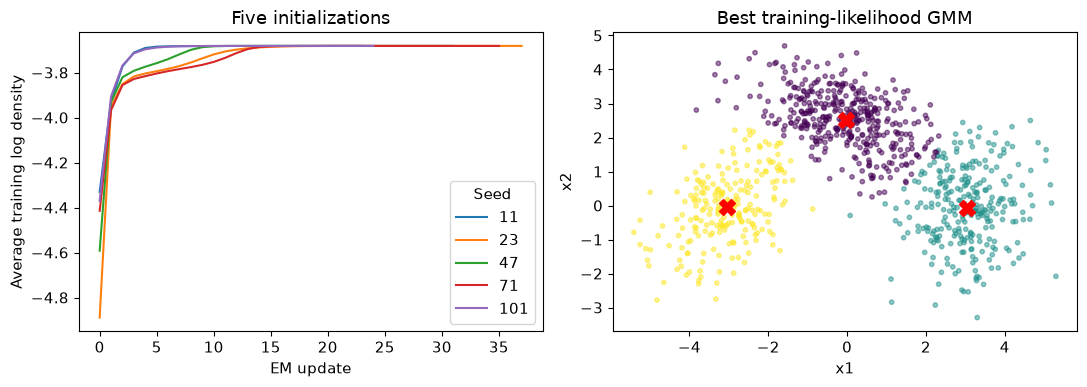

In [46]:
RESTART_SEEDS = [11, 23, 47, 71, 101]
def fit_restarts(X, K, covariance_type='full'):
    runs = [fit_em(X, K, seed=s, covariance_type=covariance_type) for s in RESTART_SEEDS]
    best = max(runs, key=lambda r:r['history'][-1])
    return best, runs

best_full, full_runs = fit_restarts(X_train, K)
for seed, run in zip(RESTART_SEEDS, full_runs):
    assert np.isfinite(run['history']).all()
    assert np.all(np.diff(run['history']) >= -1e-6)
    assert np.allclose(run['gamma'].sum(axis=1), 1)
    assert np.isclose(run['pi'].sum(), 1)
    assert np.linalg.eigvalsh(run['covs']).min()>0
    print(f'seed={seed:3d} updates={len(run["history"])-1:3d} '
          f'LL={run["history"][-1]:.4f} converged={run["converged"]}')
recomputed_g, recomputed_ld = e_step(X_train, best_full['pi'], best_full['means'], best_full['covs'])
assert np.allclose(recomputed_g, best_full['gamma'])
assert np.isclose(recomputed_ld.sum(), best_full['history'][-1])

# Component ID дурын учраас parameter recovery-г 3! permutation-аас хамгийн ойрыг сонгож харуулна.
# Жинхэнэ means энд зөвхөн fit дууссаны дараах evaluation-д орно.
order = min(permutations(range(K)),
            key=lambda p:np.sum((best_full['means'][list(p)]-TRUE_MU)**2))
order = np.array(order)
print('Aligned fitted weights:', best_full['pi'][order])
print('Aligned fitted means:\n', best_full['means'][order])
print('Aligned fitted covariances:\n', best_full['covs'][order])
print('Mean recovery RMSE:', np.sqrt(np.mean((best_full['means'][order]-TRUE_MU)**2)))

# Identical means/covariances preserve symmetry, so all 3 components stay alike.
global_mu, global_cov = moments_2d(X_train)
sym_init = (np.full(K,1/K), np.repeat(global_mu[None,:],K,axis=0),
            np.repeat(global_cov[None,:,:],K,axis=0))
sym_run = fit_em(X_train, K, init=sym_init)
print('Identical initialization final LL:', sym_run['history'][-1])
assert np.allclose(sym_run['means'], global_mu)

fig, axes = plt.subplots(1,2,figsize=(11,4))
for seed, run in zip(RESTART_SEEDS, full_runs):
    axes[0].plot(run['history']/len(X_train), label=str(seed))
axes[0].set(xlabel='EM update', ylabel='Average training log density', title='Five initializations')
axes[0].legend(title='Seed')
axes[1].scatter(*X_train.T, c=best_full['gamma'].argmax(axis=1), cmap='viridis', s=10, alpha=.5)
axes[1].scatter(*best_full['means'].T, marker='X', c='red', s=130)
axes[1].set(xlabel='x1', ylabel='x2', title='Best training-likelihood GMM')
plt.tight_layout(); plt.show()


**Тайлбар бичих:** Converged=True нь global optimum гэсэн үг үү? Mean-үүдийг бүгдийг ижил эхлүүлэхэд юу болов? Component ID-уудыг шууд харьцуулж болох уу?

TODO: Энд өөрийн тайлбарыг бичнэ.


## 8. Шинэ өгөгдөл дээр харьцуулах · 10 оноо

Нэг Gaussian, 3-component full-covariance GMM, 3-component diagonal-covariance GMM гэсэн загваруудыг **зөвхөн training data** дээр тааруул. Загвар бүрийн training болон independent holdout дундаж log-density-г тооц:

$$
\mathrm{score}(X)=\frac1{|X|}\sum_{x\in X}\log p(x\mid\hat\theta).
$$

Илүү их буюу сөрөг тохиолдолд тэг рүү ойр score нь тухайн өгөгдлийн density-г илүү сайн тайлбарлана. Training ба holdout хэмжээ өөр тул **нийт** log-likelihood-ийг хооронд нь шууд харьцуулахгүй. Энэ holdout нь хичээлийн validation түүвэр: олон загвараас сонголт хийвэл эцсийн test гэж нэрлэхгүй.

`average_log_density` бич. Diagonal GMM-д мөн training likelihood-аар 5 restarts дотроос run сонго. Holdout-оор restart сонгохгүй. Үр дүнг хүснэгт/бар графикаар харьцуулж, full covariance-ийн нэмэлт параметрүүд тустай эсэхийг тайлбарла. Finite sample учир загваруудын дарааллыг заавал нэг утгатай гэж assert хийхгүй.

**Үнэлгээ:** training/holdout үнэлгээ 4, харьцуулалт 3, тайлбар 3.


In [47]:
def average_log_density(X, pi, means, covs):
    # TODO: e_step-ийн log_density ашиглан scalar дундаж буцаа.
    _, log_density = e_step(X, pi, means, covs)
    return log_density.mean()
    raise NotImplementedError('T8: average_log_density')


Model                Train avg log p   Holdout avg log p
Single Gaussian             -4.22596            -4.19258
GMM full                    -3.68176            -3.67530
GMM diagonal                -3.72881            -3.72713


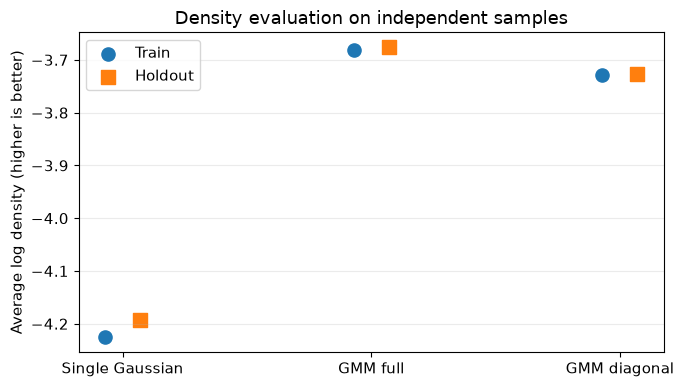

In [48]:
best_diag, diag_runs = fit_restarts(X_train, K, covariance_type='diag')
single_pi = np.ones(1)
single_means = global_mu[None,:]
single_covs = global_cov[None,:,:]
MODELS = {
    'Single Gaussian': (single_pi, single_means, single_covs),
    'GMM full': (best_full['pi'], best_full['means'], best_full['covs']),
    'GMM diagonal': (best_diag['pi'], best_diag['means'], best_diag['covs'])}
scores = {}
print(f'{"Model":18s} {"Train avg log p":>17s} {"Holdout avg log p":>19s}')
for name, params in MODELS.items():
    tr = average_log_density(X_train, *params)
    ho = average_log_density(X_holdout, *params)
    scores[name] = (tr, ho)
    assert np.isfinite([tr,ho]).all()
    print(f'{name:18s} {tr:17.5f} {ho:19.5f}')
assert np.isclose(average_log_density(X_train, **{'pi':best_full['pi'],
    'means':best_full['means'], 'covs':best_full['covs']}), best_full['history'][-1]/len(X_train))
assert np.allclose(best_diag['covs'][:,0,1], 0)
pos = np.arange(len(scores))
fig, ax = plt.subplots()
ax.scatter(pos-.07, [s[0] for s in scores.values()], s=90, marker='o', label='Train')
ax.scatter(pos+.07, [s[1] for s in scores.values()], s=90, marker='s', label='Holdout')
ax.set(xticks=pos, xticklabels=list(scores), ylabel='Average log density (higher is better)',
       title='Density evaluation on independent samples')
ax.grid(axis='y', alpha=.25)
ax.legend(); plt.tight_layout(); plt.show()


**Тайлбар бичих:** Өөрийн тоон score-уудыг ишлэн аль загвар сайн байсныг тайлбарла. Training score өсөх нь шинэ өгөгдөлд заавал сайн гэсэн үг үү? Full болон diagonal covariance-ийн ялгааг өгөгдөлтэй холбо.

TODO: Энд өөрийн тайлбарыг бичнэ.


## Нэмэлт A. Variance MLE-ийн bias-ийг турших

**Слайд 28–30. Заавал биш, үндсэн 100 оноонд ороогүй.** Жинхэнэ variance $v=2.25$, mean $2$ гэж ав. $N\in\{5,10,30,100\}$ тус бүрт 3000 бие даасан түүвэр үүсгэж, MLE variance болон unbiased variance-ийн дунджийг харьцуул.

$$
\mathbb E[\hat v_{ML}]=\frac{N-1}{N}v,\qquad \mathbb E[s^2]=v.
$$

`variance_bias_experiment` нь `(len(sizes), 4)` array буцаана. Баганууд: `N`, empirical mean MLE variance, empirical mean unbiased variance, theoretical mean MLE variance. Random sample-ийн estimate бүр онолоос зөрж болох тул олон давталтын дундажтай харьцуул.


In [49]:
def variance_bias_experiment(sizes=(5,10,30,100), repeats=3000, seed=26306):
    # TODO: нэг RNG, size=(repeats,N), мөр бүрийн mean/variance.
    # np.var бэлэн функцийн оронд хазайлтын квадратаас тооц.
    rng = np.random.default_rng(seed)
    v = 2.25 # true variance
    mu = 2.0 # true mean
    sigma = np.sqrt(v)

    results = []
    for N in sizes:
        # generate repeats samples of size N: shape (repeats, N)
        samples = rng.normal(loc=mu, scale=sigma, size=(repeats, N))

        # compute mean for each sample row
        sample_means = samples.mean(axis=1, keepdims=True)

        # compute squared deviations explicitly without np.var
        squared_diffs = (samples - sample_means) ** 2

        # MLE variance (divided by N)
        mle_vars = squared_diffs.sum(axis=1)/N

        # unbiased variance (divided by N - 1) 
        unbiased_vars = squared_diffs.sum(axis=1) / (N-1)

        # average across all repeats 
        avg_mle = mle_vars.mean()
        avg_unbiased = unbiased_vars.mean()

        # theoretical expected value of MLE variance: ((N-1)/N)*v
        theory_mle = ((N - 1)/N) * v

        results.append([N, avg_mle, avg_unbiased, theory_mle])

    return np.array(results)


    raise NotImplementedError('Optional A: variance bias')


N | avg MLE variance | avg unbiased variance | theory MLE
[[  5.       1.8301   2.2877   1.8   ]
 [ 10.       2.0424   2.2693   2.025 ]
 [ 30.       2.1624   2.2369   2.175 ]
 [100.       2.2219   2.2444   2.2275]]


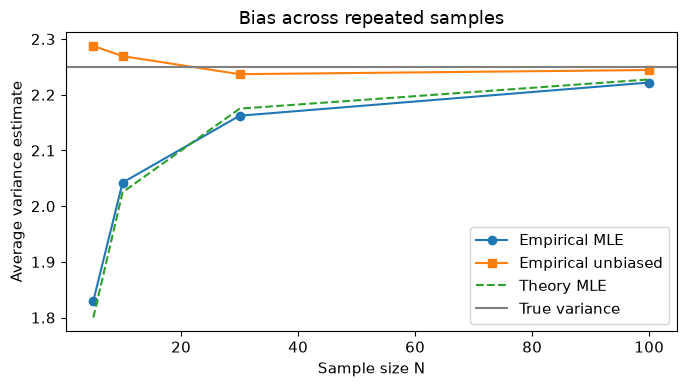

In [50]:
if RUN_OPTIONAL_A:
    # Нэмэлт A-г алгасах бол энэ нүдийг мөн алгасана.
    bias_table = variance_bias_experiment()
    print('N | avg MLE variance | avg unbiased variance | theory MLE')
    print(bias_table)
    fig, ax = plt.subplots()
    ax.plot(bias_table[:,0], bias_table[:,1], 'o-', label='Empirical MLE')
    ax.plot(bias_table[:,0], bias_table[:,2], 's-', label='Empirical unbiased')
    ax.plot(bias_table[:,0], bias_table[:,3], '--', label='Theory MLE')
    ax.axhline(2.25, color='gray', label='True variance')
    ax.set(xlabel='Sample size N', ylabel='Average variance estimate', title='Bias across repeated samples')
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print("Optional experiment skipped. Set RUN_OPTIONAL_A=True after completing it.")


**Тайлбар бичих:** N=5 болон N=100 үед MLE variance-ийн bias яаж өөрчлөгдөв? Unbiased гэдэг нь нэг түүврийн алдаа үргэлж бага гэсэн үг үү?

TODO: Энд өөрийн тайлбарыг бичнэ.


## Нэмэлт B. Covariance collapse ба MLE-ийн хязгаар

**Заавал биш.** Нэг component-ийн mean-ийг яг нэг training цэг дээр байрлуулаад covariance-ийг $\epsilon I$ болгон агшаа. Нөгөө component-ийг global Gaussian хэвээр байлгаж жинг `0.05, 0.95` гэж тогтоо. $\epsilon\in\{10^{-1},10^{-2},10^{-4},10^{-8},10^{-12}\}$ үед нийт likelihood болон тухайн төв цэгийн log-density-г тооц.

Энэ нь EM fitting биш, параметрийн зориуд сонгосон зам дагуух density туршилт. Эхний хэдэн утгад нийт likelihood заавал нэг чигт өөрчлөгдөх албагүй. Харин covariance 0 рүү агшихад төв цэгийн density хязгааргүй өсөж, бусад цэгийн density-г нөгөө component эерэг хэвээр байлгана. Иймээс чөлөөт covariance-тай mixture-ийн global MLE төгсгөлөг optimum-той байх албагүй. Eigenvalue floor эсвэл regularization хэрэглэх нь энэ хязгаарын асуудлыг өөрчилнө.


In [51]:
def collapse_experiment(X, eps_values=(1e-1,1e-2,1e-4,1e-8,1e-12)):
    # TODO: 2 components, weights [.05,.95], means [X[0], global mean].
    # Return rows [epsilon, total log-likelihood, log-density at X[0]].
    N, D = X.shape
    pi = np.array([0.05, 0.95])
    global_mu, global_cov = moments_2d(X)

    means = np.zeros((2,D))
    means[0] = X[0] # collapsing center at the first data point
    means[1] = global_mu # global background component

    results = []
    for eps in eps_values:
        covs = np.zeros((2,D,D))
        covs[0] = eps * np.eye(D) # Shrinking covariance
        covs[1] = global_cov

        # compute log-densities for all points using e_step
        _, log_density = e_step(X, pi, means, covs)

        total_ll = log_density.sum()
        center_ld = log_density[0]

        results.append([eps, total_ll, center_ld])

    return np.array(results)
    raise NotImplementedError('Optional B: covariance collapse')


epsilon | total log-likelihood | center log-density
1e-01 | -3755.09863 | -2.42223
1e-02 | -3819.94592 | -0.21701
1e-04 | -3840.45371 | 4.37685
1e-08 | -3831.24349 | 13.58707
1e-12 | -3822.03315 | 22.79741


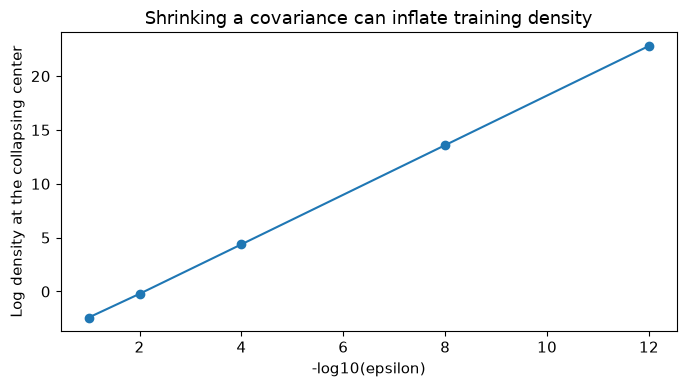

In [52]:
if RUN_OPTIONAL_B:
    # Нэмэлт B-г алгасах бол энэ нүдийг мөн алгасана.
    collapse_table = collapse_experiment(X_train)
    print('epsilon | total log-likelihood | center log-density')
    for eps, total_ll, center_ld in collapse_table:
        print(f'{eps:.0e} | {total_ll:.5f} | {center_ld:.5f}')
    assert np.isfinite(collapse_table).all()
    fig, ax = plt.subplots()
    ax.plot(-np.log10(collapse_table[:,0]), collapse_table[:,2], 'o-')
    ax.set(xlabel='-log10(epsilon)', ylabel='Log density at the collapsing center',
           title='Shrinking a covariance can inflate training density')
    plt.tight_layout(); plt.show()
else:
    print("Optional experiment skipped. Set RUN_OPTIONAL_B=True after completing it.")


**Тайлбар бичих:** Энэ туршилт EM-ийн global optimum тухай дүгнэлтийг хэрхэн өөрчилж байна вэ? reg нэмэхэд likelihood буурахгүй гэсэн тестийг яагаад шууд хэрэглэж болохгүй вэ?

TODO: Энд өөрийн тайлбарыг бичнэ.


## Цааш туршиж болох санал

Эдгээр нь хэрэгжүүлэх санал бөгөөд энэ notebook-д бэлэн бодолт ороогүй.

1. **K сонгох:** $K=1,\ldots,5$ тус бүрийг training дээр 5 эхлэлтэй сурга. Holdout average log-density болон $BIC=q\log N-2\ell_{train}$-ийг харьцуул. Full covariance-д $q=(K-1)+KD+KD(D+1)/2$, diagonal-д $q=(K-1)+2KD$. BIC бага байхыг илүүд үзнэ. Сонголтод ашигласан holdout-ийг эцсийн test гэж нэрлэхгүй.
2. **Bernoulli MLE:** слайд 17–20-ийн дагуу 0/1 өгөгдөл үүсгэж, analytic $\hat p=n_1/N$-ийг likelihood grid-ийн maximum-тай тулга. Бүгд 0 эсвэл бүгд 1 boundary case-ийг тайлбарла.
3. **Түүврийн хэмжээ ба давхцал:** N болон component mean-үүдийн хоорондох зайг өөрчил. Mean recovery, covariance estimation, soft-assignment uncertainty хэрхэн өөрчлөгдөхийг хэд хэдэн seed-ээр харьцуул.

## Илгээхээс өмнөх шалгах зүйл

- Найман үндсэн хэсгийн код, гараар бодолт, бүх тайлбар дууссан.
- Parameters нь зөв shape-тэй, covariance symmetric positive definite, weights болон responsibility мөрүүд нийлбэр1.
- Training-д holdout эсвэл жинхэнэ label ороогүй. Жинхэнэ parameter-ийг Т5-ийн posterior demo болон сургалтын дараах recovery үнэлгээнд хэрэглэсэн.
- Likelihood-ийн total/average болон density/probability утгыг ялгасан.
- Restart & Run All амжилттай. Нэмэлт A-г бөглөсөн бол `RUN_OPTIONAL_A=True`, нэмэлт B-г бөглөсөн бол `RUN_OPTIONAL_B=True` болгоно. Хийгээгүй нэмэлтийн flag-ийг `False` хэвээр үлдээнэ.
- Файлаа `Lab05_StudentID.ipynb` гэж хадгалж, үр дүн болон графикуудыг үлдээсэн.
